In [1]:
import sys
import os
from IPython.display import clear_output, display
from importnb import Notebook
from pathlib import Path
import re
import torch.nn.functional as F
from torch.utils.data import DataLoader
from collections import defaultdict
target_path = r'C:\Users\alex1\OneDrive\Alex\OneDrive\Desktop\LocalizationModel\Functions'
if target_path not in sys.path:
    sys.path.insert(0, target_path)
with Notebook():
    from Functions1 import *
    print("Success!")
target_path1 = r'C:\Users\alex1\OneDrive\Alex\OneDrive\Desktop\LocalizationModel'
if target_path1 not in sys.path:
    sys.path.insert(0, target_path1)
with Notebook():
    from DataLoader import *
    print("Success!")

Using device: cuda
Success!
Success!


# Number of Channel Divisions

In [2]:
def get_groups(channels, max_groups=8):
    for g in range(min(channels, max_groups), 0, -1):
        if channels % g == 0:
            return g
    return 1

# 2D Convolutional Block

In [3]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=True),
            nn.GroupNorm(get_groups(out_channels), out_channels,affine=True),
            nn.GELU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=True),
            nn.GroupNorm(get_groups(out_channels), out_channels,affine=True)
        )
        self.skip = nn.Identity() if in_channels == out_channels and stride == 1 else nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=True),
            nn.GroupNorm(get_groups(out_channels), out_channels,affine=True)
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.block(x) + self.skip(x))

# Stream Encoder

In [4]:
class StreamEncoder(nn.Module):
    def __init__(self, in_channels, stem_channels, stage_channels):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, stem_channels, 3, stride=2, padding=1, bias=True),
            nn.GroupNorm(get_groups(stem_channels), stem_channels,affine=True),
            nn.GELU()
        )
        stages = []
        previous = stem_channels
        for channels in stage_channels:
            stages.append(ConvBlock(previous, channels, stride=2))
            previous = channels
        self.stages = nn.ModuleList(stages)

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.reshape(b * t, c, h, w)
        stem = self.stem(x)
        features = []
        x = stem
        for stage in self.stages:
            x = stage(x)
            features.append(x)
        stem = stem.reshape(b, t, stem.shape[1], stem.shape[2], stem.shape[3])
        features = [
            f.reshape(b, t, f.shape[1], f.shape[2], f.shape[3])
            for f in features
        ]
        return stem, features

# Stream Fusion

In [5]:
class GatedFusion(nn.Module):
    def __init__(self, channels):
        super().__init__()
        hidden = max(16, channels // 2)
        self.gate = nn.Sequential(
            nn.Conv2d(channels * 3, hidden, 1, bias=True),
            nn.GroupNorm(get_groups(hidden), hidden,affine=True),
            nn.GELU(),
            nn.Conv2d(hidden, 3, 1)
        )
        self.refine = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=True),
            nn.GroupNorm(get_groups(channels), channels,affine=True),
            nn.GELU()
        )

    def forward(self, rgb, variance, flow):
        b, t, c, h, w = rgb.shape
        joined = torch.cat([rgb, variance, flow], dim=2)
        joined = joined.reshape(b * t, c * 3, h, w)
        gates = self.gate(joined)
        gates = gates.reshape(b, t, 3, h, w)
        gates = torch.softmax(gates, dim=2)
        stacked = torch.stack([rgb, variance, flow], dim=2)
        fused = (
            stacked * gates.unsqueeze(3)
        ).sum(dim=2)
        fused = fused.reshape(b * t, c, h, w)
        fused = self.refine(fused)
        fused = fused.reshape(b, t, c, h, w)
        return fused, gates

# Temporal Convolution BLock

In [6]:
class TemporalBlock(nn.Module):
    def __init__(self, channels, heads=4, use_attention=False):
        super().__init__()
        self.temporal_conv = nn.Sequential(
            nn.Conv3d(
                channels, channels, (3, 1, 1),
                padding=(1, 0, 0), groups=channels, bias=True
            ),
            nn.Conv3d(channels, channels, 1, bias=True),
            nn.GELU()
        )
        self.use_attention = use_attention
        if use_attention:
            self.norm = nn.LayerNorm(channels)
            self.attention = nn.MultiheadAttention(
                channels, heads, batch_first=True
            )
            self.attn_scale = nn.Parameter(torch.tensor(0.1))

    def forward(self, x):
        b, t, c, h, w = x.shape
        temporal = x.permute(0, 2, 1, 3, 4)
        temporal = self.temporal_conv(temporal)
        x = x + temporal.permute(0, 2, 1, 3, 4)
        if self.use_attention:
            z = x.permute(0, 3, 4, 1, 2).reshape(b * h * w, t, c)
            z_norm = self.norm(z)
            attended, _ = self.attention(
                z_norm, z_norm, z_norm, need_weights=False
            )
            z = z + self.attn_scale * attended
            x = z.reshape(b, h, w, t, c).permute(0, 3, 4, 1, 2)
        return x

# Upsampling Block

In [7]:
class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            ConvBlock(in_channels + skip_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )

    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )
        x = torch.cat([x, skip], dim=1)
        return self.block(x)

# Main Model

In [8]:
class VideoArtifactLocalizer(nn.Module):
    def __init__(self,rgb_channels=3,variance_channels=1,flow_channels=2,fusion_channels=(32,48,72,96),branch_channels=(16,24,36,48),attention_heads=4):
        super().__init__()
        self.rgb_encoder = StreamEncoder(rgb_channels, 24, fusion_channels)
        self.variance_encoder = StreamEncoder(variance_channels, 12, branch_channels)
        self.flow_encoder = StreamEncoder(flow_channels, 12, branch_channels)
        self.variance_projection = nn.ModuleList([nn.Conv2d(bc, fc, 1) for bc, fc in zip(branch_channels, fusion_channels)])
        self.flow_projection = nn.ModuleList([nn.Conv2d(bc, fc, 1) for bc, fc in zip(branch_channels, fusion_channels)])
        self.fusions = nn.ModuleList([GatedFusion(c) for c in fusion_channels])
        self.temporal = nn.ModuleList([TemporalBlock(c,heads=attention_heads,use_attention=(i >= 2)) for i, c in enumerate(fusion_channels)])
        self.decoder4 = UpBlock(96, 72, 96)
        self.decoder3 = UpBlock(96, 48, 72)
        self.decoder2 = UpBlock(72, 32, 48)
        self.decoder1 = UpBlock(48, 24, 32)
        self.final_refine = nn.Sequential(ConvBlock(32, 24),nn.Conv2d(24, 1, 1))

    def forward(self, x, return_gates=False):
        if x.ndim != 5:
            raise ValueError(
                f"Expected 5D input [B,T,C,H,W], got {tuple(x.shape)}"
            )
        if x.shape[2] != 6:
            raise ValueError(
                f"Expected 6 input channels (RGB+variance+flow), got {x.shape[2]}"
            )
        b, t, _, h, w = x.shape
        rgb = x[:, :, 0:3]
        variance = x[:, :, 3:4]
        flow = x[:, :, 4:6]
        rgb_stem, rgb_features = self.rgb_encoder(rgb)
        _, variance_features = self.variance_encoder(variance)
        _, flow_features = self.flow_encoder(flow)
        fused_features = []
        all_gates = []
        for i in range(4):
            vf = variance_features[i]
            ff = flow_features[i]
            rh, rw = rgb_features[i].shape[-2:]

            vf = self.variance_projection[i](
                vf.reshape(b * t, vf.shape[2], vf.shape[3], vf.shape[4])
            ).reshape(b, t, -1, rh, rw)

            ff = self.flow_projection[i](
                ff.reshape(b * t, ff.shape[2], ff.shape[3], ff.shape[4])
            ).reshape(b, t, -1, rh, rw)

            fused, gates = self.fusions[i](
                rgb_features[i], vf, ff
            )
            fused = self.temporal[i](fused)
            fused_features.append(fused)
            all_gates.append(gates)
        f1, f2, f3, f4 = fused_features
        def flatten_time(z):
            return z.reshape(
                b * t, z.shape[2], z.shape[3], z.shape[4]
            )
        d = self.decoder4(flatten_time(f4), flatten_time(f3))
        d = self.decoder3(d, flatten_time(f2))
        d = self.decoder2(d, flatten_time(f1))
        d = self.decoder1(d, flatten_time(rgb_stem))

        d = F.interpolate(
            d, size=(h, w), mode="bilinear", align_corners=False
        )
        logits = self.final_refine(d)
        logits = logits.reshape(b, t, 1, h, w)
        if return_gates:
            return logits, all_gates
        return logits

# Loss Function

In [9]:
def segmentation_loss(
    logits,
    targets,
    pos_weight=1.0,
    bce_weight=1.0,
    dice_weight=1.0,
    smooth=1.0
):
    logits = logits.float()
    targets = targets.float()
    pw = torch.tensor(
        float(pos_weight), device=logits.device
    )
    bce = F.binary_cross_entropy_with_logits(
        logits, targets, pos_weight=pw
    )
    probabilities = torch.sigmoid(logits)
    dimensions = (2, 3, 4)
    intersection = (probabilities * targets).sum(dim=dimensions)
    denominator = (
        probabilities.sum(dim=dimensions) +
        targets.sum(dim=dimensions)
    )
    dice = (
        2.0 * intersection + smooth
    ) / (denominator + smooth)
    dice_loss = 1.0 - dice.mean()
    total = bce_weight * bce + dice_weight * dice_loss
    return total, {
        "bce": bce.detach(),
        "dice": dice_loss.detach()
    }

# Generate Batches

In [10]:
def prepare_batch(x, y, device):
    x = torch.as_tensor(x, dtype=torch.float32)
    y = torch.as_tensor(y, dtype=torch.float32)
    if x.ndim != 5 or y.ndim != 5:
        raise ValueError("X and Y must both be 5D tensors.")
    # Convert [B,C,T,H,W] to [B,T,C,H,W].
    if x.shape[2] != 6 and x.shape[1] == 6:
        x = x.permute(0, 2, 1, 3, 4)
    if y.shape[2] != 1 and y.shape[1] == 1:
        y = y.permute(0, 2, 1, 3, 4)
    if x.shape[2] != 6:
        raise ValueError(f"Invalid input shape: {tuple(x.shape)}")
    if y.shape[2] != 1:
        raise ValueError(f"Invalid mask shape: {tuple(y.shape)}")
    if x.shape[:2] != y.shape[:2] or x.shape[-2:] != y.shape[-2:]:
        raise ValueError(
            f"Input/mask mismatch: X={tuple(x.shape)}, Y={tuple(y.shape)}"
        )
    x = x.to(device, non_blocking=True)
    y = (y > 0.5).float().to(device, non_blocking=True)
    return x, y

In [11]:
def unpack_batch(batch):
    if isinstance(batch, dict):
        x = batch.get("X", batch.get("input", batch.get("video")))
        y = batch.get("Y", batch.get("mask", batch.get("target")))
        if x is None or y is None:
            raise ValueError("Dictionary batch must contain X/input and Y/mask.")
        return x, y
    if isinstance(batch, (tuple, list)) and len(batch) >= 2:
        return batch[0], batch[1]
    raise ValueError("Each batch must contain (X, Y) or a compatible dictionary.")

In [12]:
def get_batches(source, steps=None):
    if callable(source):
        if steps is None:
            raise ValueError(
                "steps_per_epoch is required when using a batch function."
            )
        for _ in range(steps):
            yield source()
    else:
        yield from source

# Evaluation Metrics

In [13]:
def update_metrics(stats, logits, targets, threshold=0.5):
    predictions = torch.sigmoid(logits.detach()) >= threshold
    actual = targets >= 0.5
    stats["tp"] += (predictions & actual).sum().item()
    stats["fp"] += (predictions & ~actual).sum().item()
    stats["fn"] += (~predictions & actual).sum().item()
    actual_empty = ~actual.flatten(2).any(dim=2)
    predicted_any = predictions.flatten(2).any(dim=2)
    stats["empty_fp"] += (
        actual_empty & predicted_any
    ).sum().item()
    stats["empty_frames"] += actual_empty.sum().item()

def calculate_metrics(stats):
    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    empty_fp_rate = (
        stats["empty_fp"] / (stats["empty_frames"] + 1e-8)
    )
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "empty_frame_fp_rate": empty_fp_rate
    }

# Run Single Epoch

In [14]:
def run_epoch(
    model,
    data_source,
    device,
    optimizer=None,
    scaler=None,
    use_amp=True,
    pos_weight=1.0,
    bce_weight=1.0,
    dice_weight=1.0,
    threshold=0.5,
    grad_clip=1.0,
    steps=None
):
    training = optimizer is not None
    model.train(training)
    stats = defaultdict(float)
    number_of_batches = 0
    for batch in get_batches(data_source, steps):
        x, y = unpack_batch(batch)
        x, y = prepare_batch(x, y, device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        amp_enabled = use_amp and device.type == "cuda"
        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                logits = model(x)
                loss, loss_parts = segmentation_loss(
                    logits,
                    y,
                    pos_weight=pos_weight,
                    bce_weight=bce_weight,
                    dice_weight=dice_weight
                )
            if training:
                if scaler is not None and scaler.is_enabled():
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(), grad_clip
                    )
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(), grad_clip
                    )
                    optimizer.step()
        stats["loss"] += loss.detach().item()
        stats["bce"] += loss_parts["bce"].item()
        stats["dice_loss"] += loss_parts["dice"].item()
        update_metrics(stats, logits, y, threshold)
        number_of_batches += 1
    if number_of_batches == 0:
        raise RuntimeError("No batches were produced.")
    results = {
        "loss": stats["loss"] / number_of_batches,
        "bce": stats["bce"] / number_of_batches,
        "dice_loss": stats["dice_loss"] / number_of_batches
    }
    results.update(calculate_metrics(stats))
    return results

# Display Function

In [15]:
def display_video_predictions(
    model,
    batch,
    device,
    video_index=0,
    threshold=0.5,
    show_binary=False,
    figsize=None
):
    was_training = model.training
    model.eval()
    x, y = unpack_batch(batch)
    x, y = prepare_batch(x, y, device)
    if video_index < 0 or video_index >= x.shape[0]:
        raise IndexError(
            f"video_index={video_index} is invalid for batch size {x.shape[0]}"
        )
    with torch.no_grad():
        logits = model(x)
        probabilities = torch.sigmoid(logits)
    # Select one video from the batch.
    rgb = x[video_index, :, 0:3].detach().cpu().float().numpy()
    gt = y[video_index, :, 0].detach().cpu().numpy()
    pred = probabilities[video_index, :, 0].detach().cpu().numpy()
    # [T,3,H,W] -> [T,H,W,3].
    rgb = np.moveaxis(rgb, 1, -1)
    rgb = np.clip(rgb, 0, 1)
    n_frames = rgb.shape[0]
    if figsize is None:
        figsize = (14, max(3, n_frames * 2.8))
    fig, axes = plt.subplots(
        n_frames, 3,
        figsize=figsize,
        squeeze=False
    )
    for i in range(n_frames):
        # Input RGB frame.
        axes[i, 0].imshow(cv2.cvtColor(rgb[i],cv2.COLOR_BGR2RGB))
        axes[i, 0].set_ylabel(f"Frame {i + 1}", fontsize=10)
        # Ground-truth mask.
        axes[i, 1].imshow(
            gt[i],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        # Predicted probability map.
        im = axes[i, 2].imshow(
            pred[i],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        if show_binary:
            binary = (pred[i] >= threshold).astype(np.float32)
            axes[i, 2].contour(
                binary,
                levels=[0.5],
                colors=["cyan"],
                linewidths=0.8
            )
        for j in range(3):
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
    axes[0, 0].set_title("Input RGB", fontsize=12)
    axes[0, 1].set_title("Ground Truth", fontsize=12)
    axes[0, 2].set_title("Predicted Probability", fontsize=12)
    fig.colorbar(
        im,
        ax=axes[:, 2].tolist(),
        fraction=0.025,
        pad=0.02,
        label="Manipulation probability"
    )
    fig.suptitle(
        f"Video {video_index} | Prediction threshold: {threshold:.2f}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    if was_training:
        model.train()

# Training Function

In [16]:
def train_model(
    model, train_loader, val_loader=None, epochs=50, device=None,
    learning_rate=1e-4, weight_decay=1e-4, pos_weight=1.0,
    bce_weight=1.0, dice_weight=1.0, use_amp=True, threshold=0.5,
    grad_clip=1.0, steps_per_epoch=None, val_steps=None, patience=10,
    min_delta=1e-4, save_path="best_video_localizer.pth",
    latest_path="latest_video_localizer.pth", resume_path=None,
    display_batch=None, N_dis=5, display_video_index=0,
    display_threshold=0.5, display_binary=False
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(device)

    if N_dis < 1:
        raise ValueError("N_dis must be >= 1.")

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-7
    )

    amp_enabled = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

    history = defaultdict(list)
    best_loss = float("inf")
    epochs_without_improvement = 0
    start_epoch = 1

    # Resume previous training.
    if resume_path is not None:
        if not os.path.isfile(resume_path):
            raise FileNotFoundError(f"Checkpoint not found: {resume_path}")

        try:
            checkpoint = torch.load(
                resume_path, map_location=device, weights_only=False
            )
        except TypeError:
            checkpoint = torch.load(resume_path, map_location=device)

        model.load_state_dict(checkpoint["model_state_dict"])

        if "optimizer_state_dict" in checkpoint:
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        if "scheduler_state_dict" in checkpoint:
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

        if "scaler_state_dict" in checkpoint and scaler.is_enabled():
            scaler.load_state_dict(checkpoint["scaler_state_dict"])

        best_loss = checkpoint.get("best_loss", float("inf"))
        epochs_without_improvement = checkpoint.get(
            "epochs_without_improvement", 0
        )

        history.update(checkpoint.get("history", {}))
        start_epoch = checkpoint.get("epoch", 0) + 1

        print(f"\nResuming training from: {resume_path}")
        print(f"Last saved epoch: {start_epoch - 1}")
        print(f"Best loss: {best_loss:.6f}")
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.2e}")

        if "scaler_state_dict" not in checkpoint:
            print("No saved AMP scaler state. Using a fresh scaler.")

    if start_epoch > epochs:
        print(f"Training already reached epoch {start_epoch - 1}.")
        return model, dict(history)

    def make_checkpoint(epoch):
        return {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_loss": best_loss,
            "epochs_without_improvement": epochs_without_improvement,
            "history": dict(history)
        }

    def save_checkpoint(path, epoch):
        if path is None:
            return
        directory = os.path.dirname(path)
        if directory:
            os.makedirs(directory, exist_ok=True)
        torch.save(make_checkpoint(epoch), path)

    for epoch in range(start_epoch, epochs + 1):

        train_metrics = run_epoch(
            model=model,
            data_source=train_loader,
            device=device,
            optimizer=optimizer,
            scaler=scaler,
            use_amp=use_amp,
            pos_weight=pos_weight,
            bce_weight=bce_weight,
            dice_weight=dice_weight,
            threshold=threshold,
            grad_clip=grad_clip,
            steps=steps_per_epoch
        )

        if val_loader is not None:
            val_metrics = run_epoch(
                model=model,
                data_source=val_loader,
                device=device,
                use_amp=use_amp,
                pos_weight=pos_weight,
                bce_weight=bce_weight,
                dice_weight=dice_weight,
                threshold=threshold,
                steps=val_steps
            )
            monitored_loss = val_metrics["loss"]
        else:
            val_metrics = None
            monitored_loss = train_metrics["loss"]

        scheduler.step(monitored_loss)

        for key, value in train_metrics.items():
            history["train_" + key].append(value)

        if val_metrics is not None:
            for key, value in val_metrics.items():
                history["val_" + key].append(value)

        current_lr = optimizer.param_groups[0]["lr"]
        history["learning_rate"].append(current_lr)

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Train F1: {train_metrics['f1']:.4f} | "
            f"Train IoU: {train_metrics['iou']:.4f} | "
            f"Train Empty-FP: {train_metrics['empty_frame_fp_rate']:.4f}"
        )

        if val_metrics is not None:
            print(
                f"                 "
                f"Val Loss: {val_metrics['loss']:.4f} | "
                f"Val F1: {val_metrics['f1']:.4f} | "
                f"Val IoU: {val_metrics['iou']:.4f} | "
                f"Val Empty-FP: {val_metrics['empty_frame_fp_rate']:.4f}"
            )

        print(f"                 Learning rate: {current_lr:.2e}")

        improved = monitored_loss < best_loss - min_delta

        if improved:
            best_loss = monitored_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Save best checkpoint when performance improves.
        if improved:
            save_checkpoint(save_path, epoch)
            if save_path is not None:
                print(f"                 Saved best model: {save_path}")

        # Save latest checkpoint after EVERY completed epoch.
        save_checkpoint(latest_path, epoch)
        if latest_path is not None:
            print(f"                 Saved latest checkpoint: {latest_path}")

        # Generate a new visualization batch every N_dis epochs.
        if display_batch is not None and epoch % N_dis == 0:

            print(f"\nGenerating new visualization video for epoch {epoch}...")

            current_display_batch = (
                display_batch()
                if callable(display_batch)
                else display_batch
            )

            display_video_predictions(
                model=model,
                batch=current_display_batch,
                device=device,
                video_index=display_video_index,
                threshold=display_threshold,
                show_binary=display_binary
            )

        if val_loader is not None and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    return model, dict(history)


# Training

Epoch 001/50 | Train Loss: 1.1966 | Train F1: 0.0778 | Train IoU: 0.0405 | Train Empty-FP: 0.0899
                 Learning rate: 2.00e-03
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 002/50 | Train Loss: 1.0943 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 003/50 | Train Loss: 1.0863 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 004/50 | T

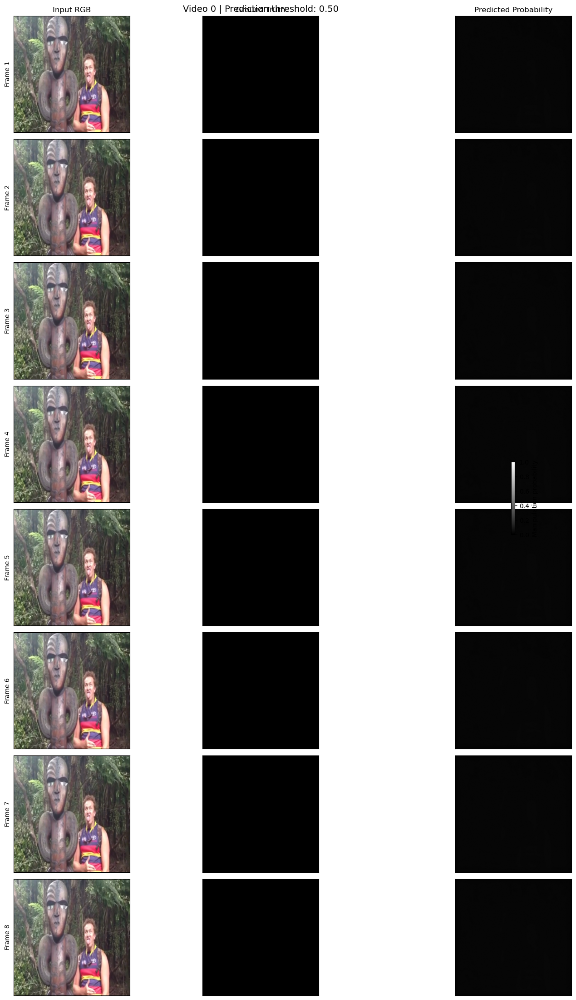

Epoch 006/50 | Train Loss: 1.0852 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 007/50 | Train Loss: 1.1315 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 008/50 | Train Loss: 1.0886 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 009/50 | Train Loss: 1.0434 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 2.00e-03
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/Video

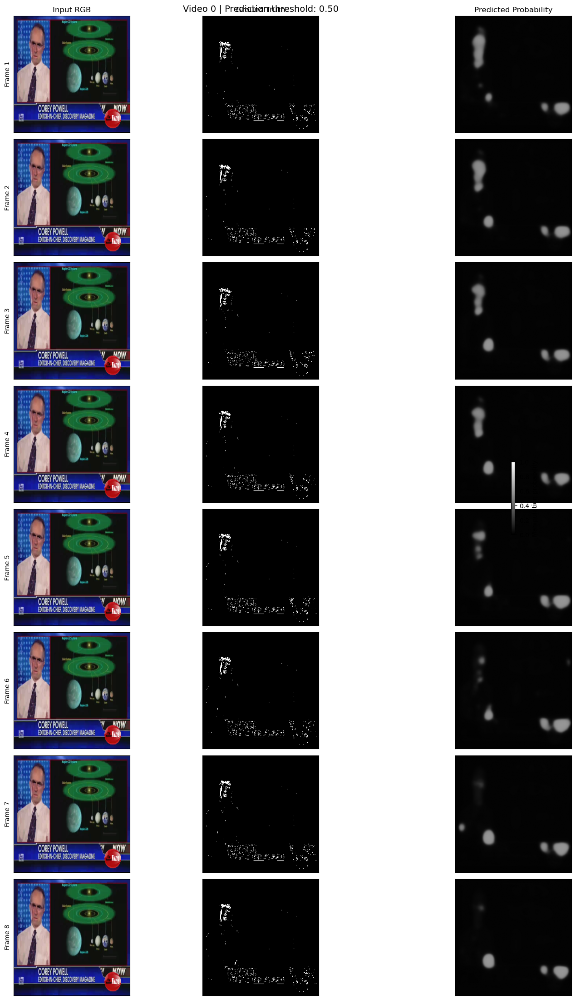

Epoch 011/50 | Train Loss: 1.0220 | Train F1: 0.0522 | Train IoU: 0.0268 | Train Empty-FP: 0.7549
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 012/50 | Train Loss: 1.0269 | Train F1: 0.0712 | Train IoU: 0.0369 | Train Empty-FP: 1.0000
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 013/50 | Train Loss: 1.0270 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0811
                 Learning rate: 2.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 014/50 | Train Loss: 1.0733 | Train F1: 0.0000 | Train IoU: 0.0000 | Train Empty-FP: 0.0000
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 015/50 | Train Loss: 1.0072 | Train F1: 0.0636

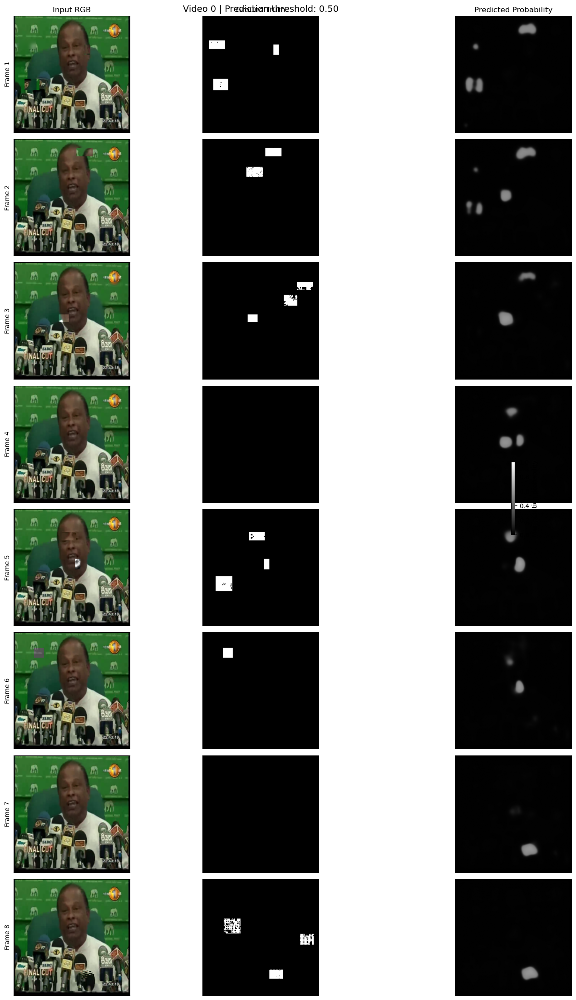

Epoch 016/50 | Train Loss: 1.1014 | Train F1: 0.0480 | Train IoU: 0.0246 | Train Empty-FP: 0.9694
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 017/50 | Train Loss: 1.0761 | Train F1: 0.0513 | Train IoU: 0.0263 | Train Empty-FP: 0.7216
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 018/50 | Train Loss: 1.0691 | Train F1: 0.0698 | Train IoU: 0.0362 | Train Empty-FP: 1.0000
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 019/50 | Train Loss: 1.0023 | Train F1: 0.1545 | Train IoU: 0.0837 | Train Empty-FP: 0.9146
                 Learning rate: 1.00e-03
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/Video

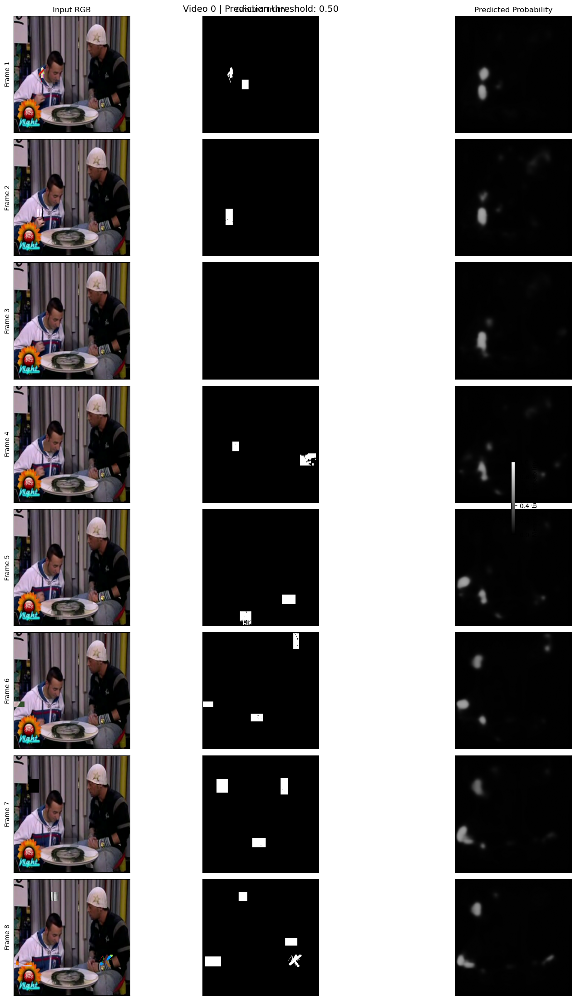

Epoch 021/50 | Train Loss: 1.0568 | Train F1: 0.0532 | Train IoU: 0.0273 | Train Empty-FP: 0.8919
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 022/50 | Train Loss: 1.0396 | Train F1: 0.0825 | Train IoU: 0.0430 | Train Empty-FP: 0.9817
                 Learning rate: 1.00e-03
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 023/50 | Train Loss: 1.0206 | Train F1: 0.0716 | Train IoU: 0.0371 | Train Empty-FP: 0.9012
                 Learning rate: 5.00e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 024/50 | Train Loss: 1.0293 | Train F1: 0.1152 | Train IoU: 0.0611 | Train Empty-FP: 0.9674
                 Learning rate: 5.00e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 025/50 | Train Loss: 1.1728 | Train F1: 0.0526

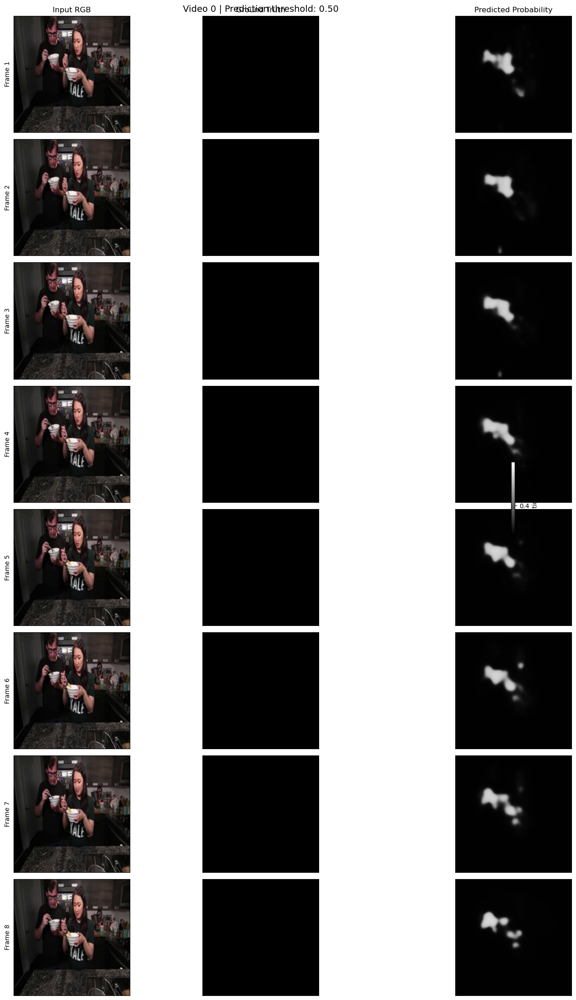

Epoch 026/50 | Train Loss: 1.0943 | Train F1: 0.0886 | Train IoU: 0.0463 | Train Empty-FP: 1.0000
                 Learning rate: 5.00e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 027/50 | Train Loss: 0.9949 | Train F1: 0.1209 | Train IoU: 0.0644 | Train Empty-FP: 0.9615
                 Learning rate: 5.00e-04
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 028/50 | Train Loss: 1.0185 | Train F1: 0.0496 | Train IoU: 0.0255 | Train Empty-FP: 0.8978
                 Learning rate: 5.00e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 029/50 | Train Loss: 1.0289 | Train F1: 0.0427 | Train IoU: 0.0218 | Train Empty-FP: 0.4649
                 Learning rate: 5.00e-04
                 Saved latest checkpoint: Checkpoints/Video

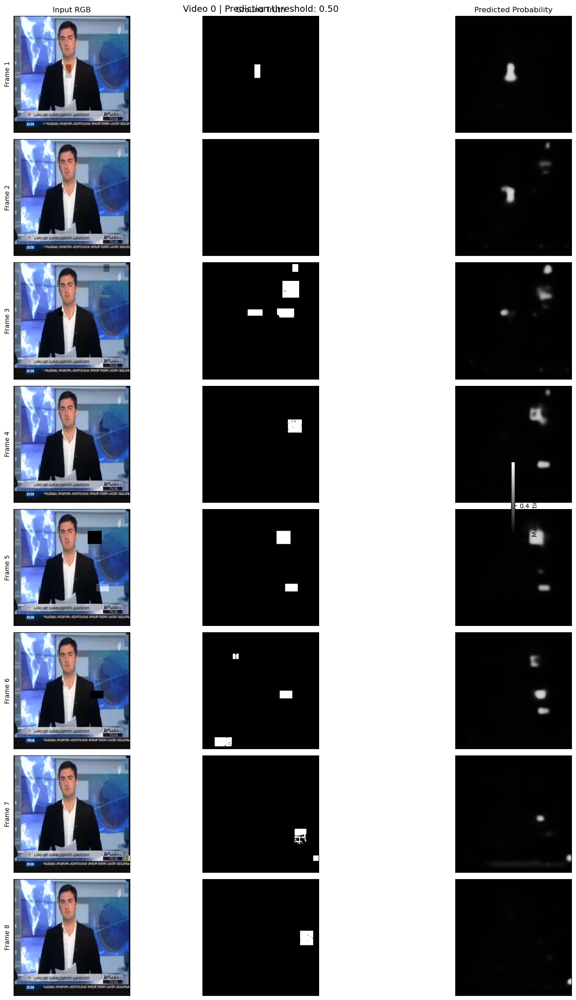

Epoch 031/50 | Train Loss: 1.0201 | Train F1: 0.1000 | Train IoU: 0.0527 | Train Empty-FP: 0.8333
                 Learning rate: 2.50e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 032/50 | Train Loss: 1.0969 | Train F1: 0.0744 | Train IoU: 0.0386 | Train Empty-FP: 1.0000
                 Learning rate: 2.50e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 033/50 | Train Loss: 1.0216 | Train F1: 0.1462 | Train IoU: 0.0789 | Train Empty-FP: 1.0000
                 Learning rate: 2.50e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 034/50 | Train Loss: 1.0749 | Train F1: 0.0368 | Train IoU: 0.0187 | Train Empty-FP: 0.9326
                 Learning rate: 2.50e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 035/50 | Train Loss: 1.0222 | Train F1: 0.1281

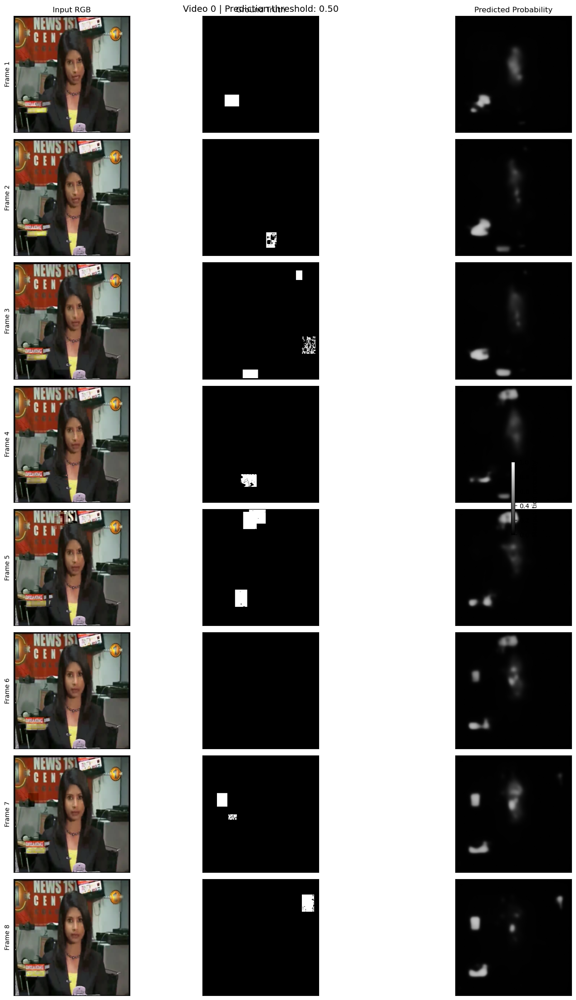

Epoch 036/50 | Train Loss: 0.9972 | Train F1: 0.1316 | Train IoU: 0.0704 | Train Empty-FP: 0.8962
                 Learning rate: 1.25e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 037/50 | Train Loss: 1.4977 | Train F1: 0.0040 | Train IoU: 0.0020 | Train Empty-FP: 0.8542
                 Learning rate: 1.25e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 038/50 | Train Loss: 0.9825 | Train F1: 0.1662 | Train IoU: 0.0907 | Train Empty-FP: 0.8500
                 Learning rate: 1.25e-04
                 Saved best model: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 039/50 | Train Loss: 1.0428 | Train F1: 0.0612 | Train IoU: 0.0315 | Train Empty-FP: 0.7826
                 Learning rate: 1.25e-04
                 Saved latest checkpoint: Checkpoints/Video

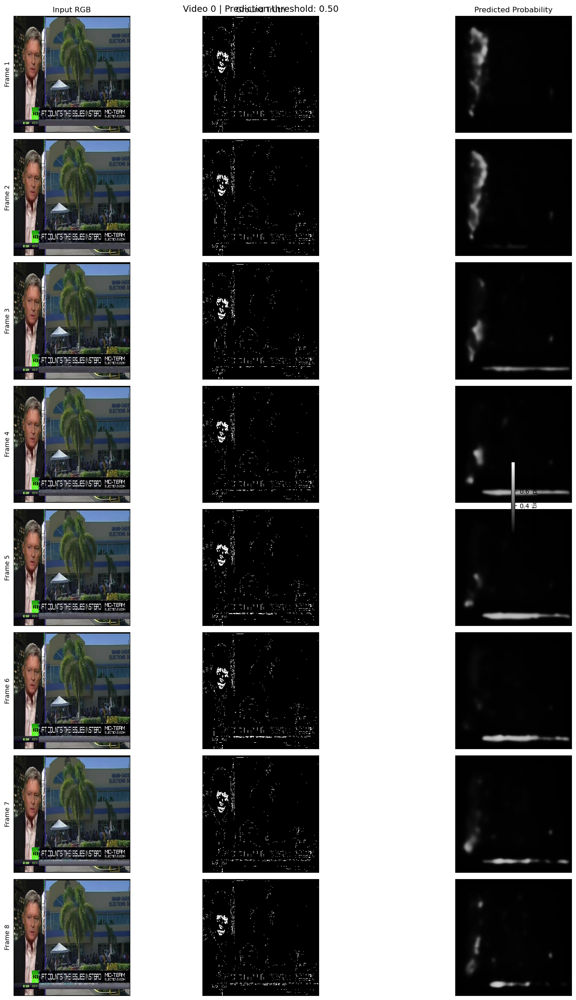

Epoch 041/50 | Train Loss: 1.0124 | Train F1: 0.1329 | Train IoU: 0.0712 | Train Empty-FP: 0.9792
                 Learning rate: 1.25e-04
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 042/50 | Train Loss: 1.0556 | Train F1: 0.0859 | Train IoU: 0.0449 | Train Empty-FP: 0.9898
                 Learning rate: 6.25e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 043/50 | Train Loss: 1.0471 | Train F1: 0.1053 | Train IoU: 0.0556 | Train Empty-FP: 1.0000
                 Learning rate: 6.25e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 044/50 | Train Loss: 1.0349 | Train F1: 0.1120 | Train IoU: 0.0593 | Train Empty-FP: 1.0000
                 Learning rate: 6.25e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 045/50 | Train Loss: 1.1973 | Train F1: 0.0637

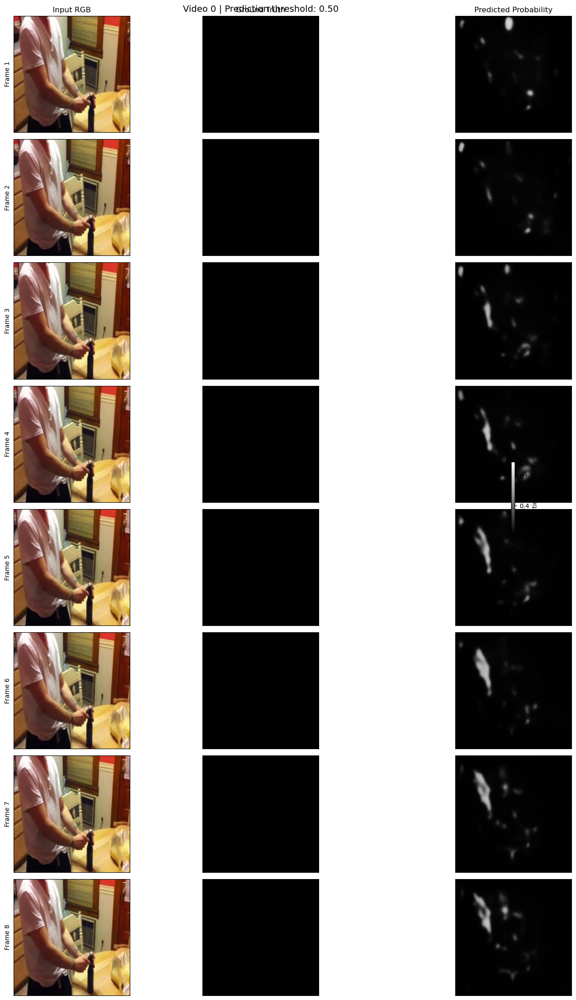

Epoch 046/50 | Train Loss: 1.0833 | Train F1: 0.0601 | Train IoU: 0.0310 | Train Empty-FP: 0.9518
                 Learning rate: 3.13e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 047/50 | Train Loss: 1.0056 | Train F1: 0.1188 | Train IoU: 0.0632 | Train Empty-FP: 0.9558
                 Learning rate: 3.13e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 048/50 | Train Loss: 1.0354 | Train F1: 0.0975 | Train IoU: 0.0513 | Train Empty-FP: 0.9762
                 Learning rate: 3.13e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 049/50 | Train Loss: 1.0965 | Train F1: 0.0576 | Train IoU: 0.0297 | Train Empty-FP: 0.8136
                 Learning rate: 3.13e-05
                 Saved latest checkpoint: Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth
Epoch 050/50 | Train Loss: 0.9841 | Train F1: 0.1817

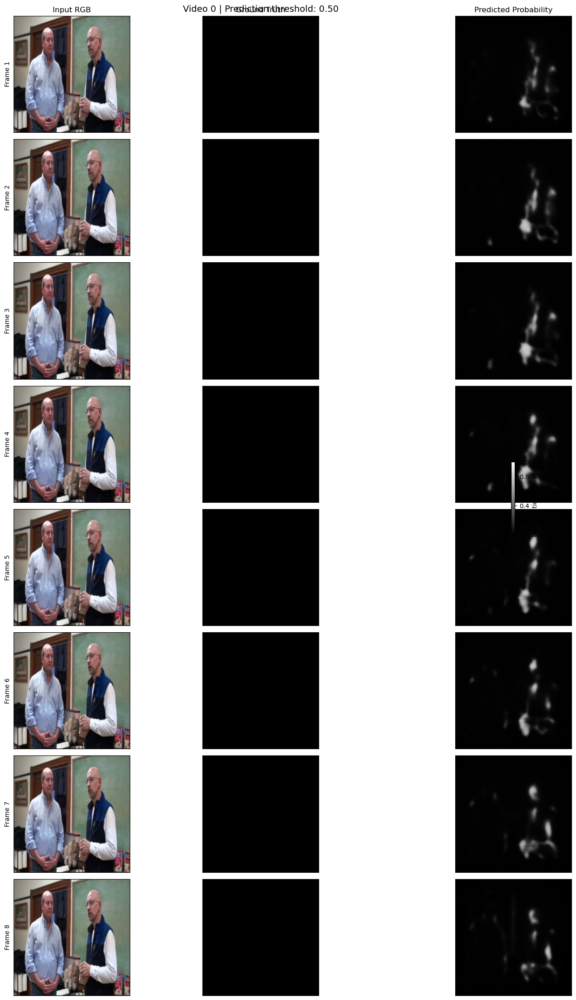

In [19]:
display_batch_fn = lambda: generate_video_batch(batch_size=1,n_frames=N_FRAMES,resize_shape=RESIZE_SHAPE,tf_thresh=0.35,device="cpu",channels_first=False)
BATCH_SIZE = 2
train_batch_fn = lambda: generate_video_batch(batch_size=BATCH_SIZE,n_frames=N_FRAMES,resize_shape=RESIZE_SHAPE,tf_thresh=0.5,device="cpu",
                                              channels_first=False)
model = VideoArtifactLocalizer()
model, history = train_model(model=model,train_loader=train_batch_fn,val_loader=None,epochs=50,steps_per_epoch=10,device=device,learning_rate=2e-3,
                             patience=10,save_path="Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth",
                             latest_path="Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth",
                             display_batch=display_batch_fn,N_dis=5,display_binary=False)

In [20]:
checkpoint = torch.load(
    "Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth",
    map_location=device,
    weights_only=False
)

model = VideoArtifactLocalizer().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Best loss:", checkpoint["best_loss"])

Loaded epoch: 50
Best loss: 0.9825180649757386


In [22]:
model.eval()
X,_ = generate_video_batch(batch_size=2,n_frames=N_FRAMES,resize_shape=RESIZE_SHAPE,tf_thresh=0.5,device=device,channels_first=False)
with torch.no_grad():
    logits, gates = model(X, return_gates=True)
    predictions = torch.sigmoid(logits)

print("Predictions:", predictions.shape)

for i, gate in enumerate(gates):
    print(f"Fusion stage {i+1}:", gate.shape)

Predictions: torch.Size([2, 8, 1, 258, 258])
Fusion stage 1: torch.Size([2, 8, 3, 65, 65])
Fusion stage 2: torch.Size([2, 8, 3, 33, 33])
Fusion stage 3: torch.Size([2, 8, 3, 17, 17])
Fusion stage 4: torch.Size([2, 8, 3, 9, 9])
